In [1]:
import pandas as pd
df = pd.read_csv(r'C:\Users\jayat\jupyter python\Dataset.csv')
display(df.head())
print("Data's Shape (Rows, Columns):", df.shape)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,?,0,5,27,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1


Data's Shape (Rows, Columns): (17379, 17)


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   instant     17379 non-null  int64
 1   dteday      17379 non-null  str  
 2   season      17379 non-null  str  
 3   yr          17379 non-null  str  
 4   mnth        17379 non-null  str  
 5   hr          17379 non-null  int64
 6   holiday     17379 non-null  str  
 7   weekday     17379 non-null  int64
 8   workingday  17379 non-null  str  
 9   weathersit  17379 non-null  str  
 10  temp        17379 non-null  str  
 11  atemp       17379 non-null  str  
 12  hum         17379 non-null  str  
 13  windspeed   17379 non-null  str  
 14  casual      17379 non-null  str  
 15  registered  17379 non-null  str  
 16  cnt         17379 non-null  int64
dtypes: int64(4), str(13)
memory usage: 3.3 MB


In [3]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [4]:
for col in df.columns:
    count = (df[col] == '?').sum()
    if count > 0:
        print(f"'{col}' no of times appeared {count} .")

'season' no of times appeared 6 .
'yr' no of times appeared 1 .
'mnth' no of times appeared 1 .
'holiday' no of times appeared 1 .
'workingday' no of times appeared 5 .
'weathersit' no of times appeared 4 .
'temp' no of times appeared 11 .
'atemp' no of times appeared 6 .
'hum' no of times appeared 6 .
'windspeed' no of times appeared 5 .
'casual' no of times appeared 1 .
'registered' no of times appeared 1 .


In [5]:
df.describe()

,instant,hr,weekday,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000
mean,8690.0000,11.546752,3.003683,189.463088
std,5017.0295,6.914405,2.005771,181.387599
min,1.0000,0.000000,0.000000,1.000000
25%,4345.5000,6.000000,1.000000,40.000000
50%,8690.0000,12.000000,3.000000,142.000000
75%,13034.5000,18.000000,5.000000,281.000000
max,17379.0000,23.000000,6.000000,977.000000


In [6]:
cat_cols = ['season', 'yr', 'mnth', 'holiday', 'workingday', 'weathersit']

print("--- Categorical Columns Check ---")
for col in cat_cols:
    print(f"\nColumn: {col}")
    print(df[col].value_counts()) 

--- Categorical Columns Check ---

Column: season
season
fall        4496
summer      4409
springer    4236
winter      4232
?              6
Name: count, dtype: int64

Column: yr
yr
2012    8734
2011    8644
?          1
Name: count, dtype: int64

Column: mnth
mnth
5     1488
7     1488
12    1482
8     1475
3     1473
10    1451
6     1440
4     1437
9     1437
11    1437
1     1429
2     1341
?        1
Name: count, dtype: int64

Column: holiday
holiday
No     16878
Yes      500
?          1
Name: count, dtype: int64

Column: workingday
workingday
Working Day    11862
No work         5512
?                  5
Name: count, dtype: int64

Column: weathersit
weathersit
Clear         11412
Mist           4541
Light Snow     1419
?                 4
Heavy Rain        3
Name: count, dtype: int64


In [7]:
import pandas as pd
num_cols = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered']
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
print(df[num_cols].isnull().sum())

temp          11
atemp          6
hum            6
windspeed      5
casual         1
registered     1
dtype: int64


In [8]:
# List of categorical columns containing invalid '?' characters
cat_cols = ['season', 'yr', 'mnth', 'holiday', 'workingday', 'weathersit']

# Replace '?' with NaN and impute missing values using the mode
for col in cat_cols:
    df[col] = df[col].replace('?', pd.NA)
    mode_value = df[col].mode()[0]
    df[col] = df[col].fillna(mode_value)

print("Categorical columns have been successfully imputed using Mode.")

Categorical columns have been successfully imputed using Mode.


In [9]:
# List of numerical columns with missing values (NaN)
num_cols = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered']

# Impute missing values using the median of each respective column
for col in num_cols:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

print("Numerical columns have been successfully imputed using Median.")

Numerical columns have been successfully imputed using Median.


In [10]:
# Verify if any missing values or '?' characters remain in the dataset
total_missing = df.isnull().sum().sum()
total_question_marks = (df == '?').sum().sum()

print(f"Total missing values remaining: {total_missing}")
print(f"Total '?' characters remaining: {total_question_marks}")

Total missing values remaining: 0
Total '?' characters remaining: 0


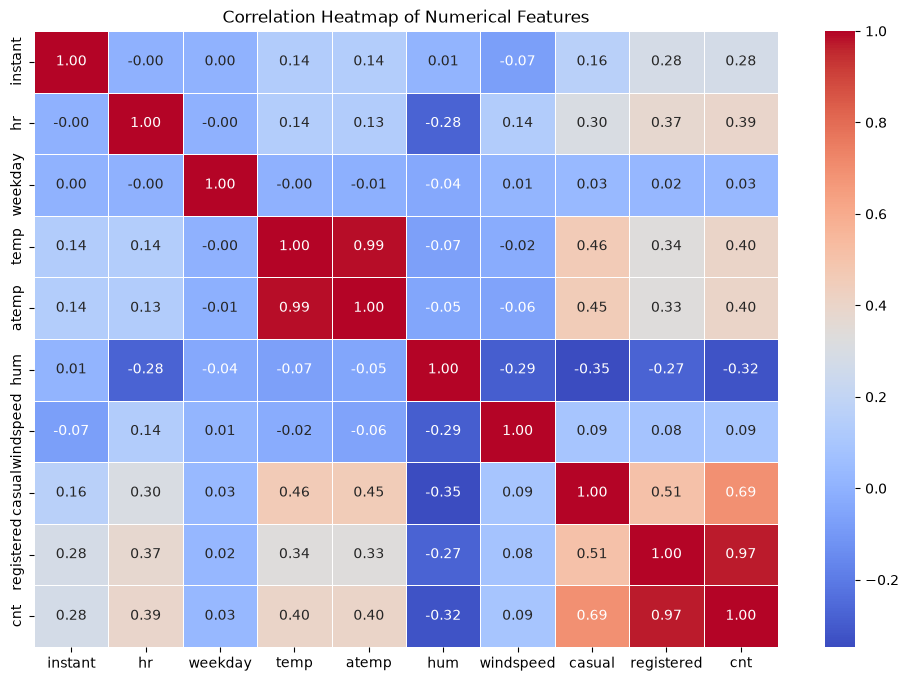

In [11]:
# Correlation matrix and Heatmap
# Select only numerical columns for correlation
import matplotlib.pyplot as plt
import seaborn as sns
numerical_data = df.select_dtypes(include=['int64', 'float64'])

# Calculate the correlation matrix
corr_matrix = numerical_data.corr()

# Plotting the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

C:\Users\jayat\AppData\Local\Temp\ipykernel_18636\4239994078.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='season', y='cnt', data=df, ax=axes[0], palette='viridis')
C:\Users\jayat\AppData\Local\Temp\ipykernel_18636\4239994078.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='weathersit', y='cnt', data=df, ax=axes[1], palette='coolwarm')


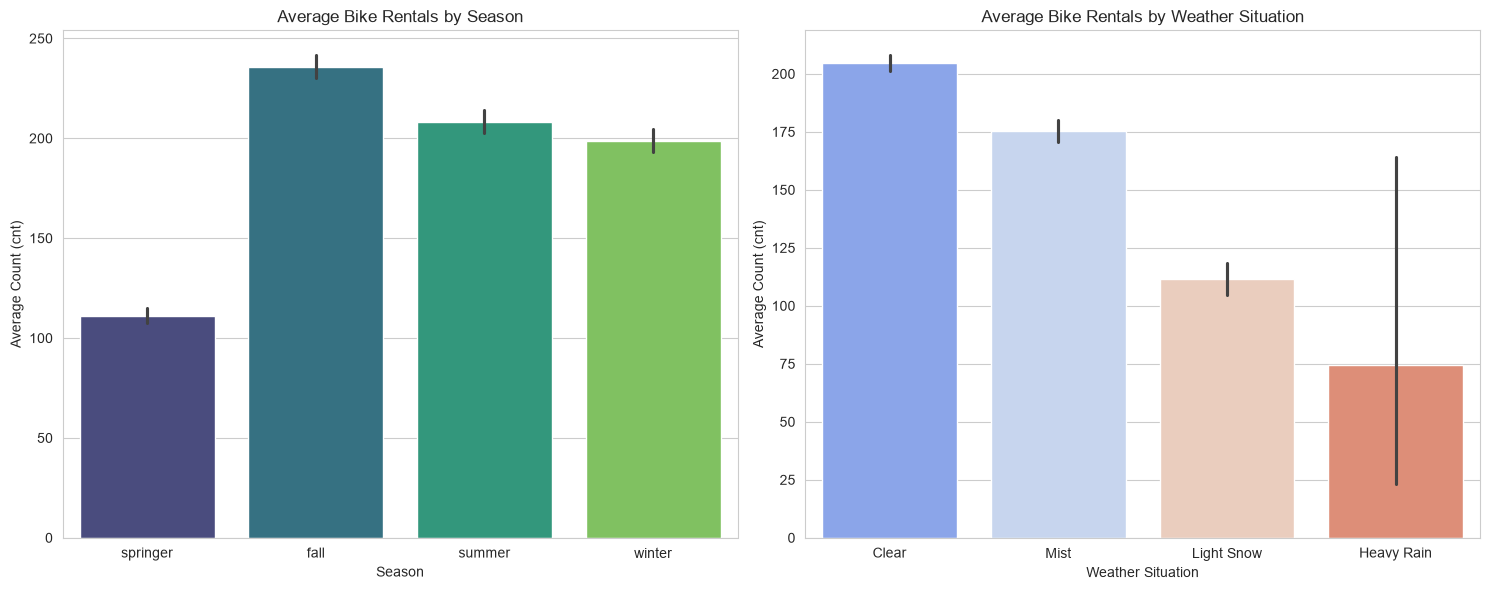

In [12]:
# Set the background style for our plots
sns.set_style("whitegrid")

# Create a figure with 2 subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Average bike rentals by Season
sns.barplot(x='season', y='cnt', data=df, ax=axes[0], palette='viridis')
axes[0].set_title('Average Bike Rentals by Season')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Average Count (cnt)')

# Plot 2: Average bike rentals by Weather Situation
sns.barplot(x='weathersit', y='cnt', data=df, ax=axes[1], palette='coolwarm')
axes[1].set_title('Average Bike Rentals by Weather Situation')
axes[1].set_xlabel('Weather Situation')
axes[1].set_ylabel('Average Count (cnt)')

# Display the plots
plt.tight_layout()
plt.show()

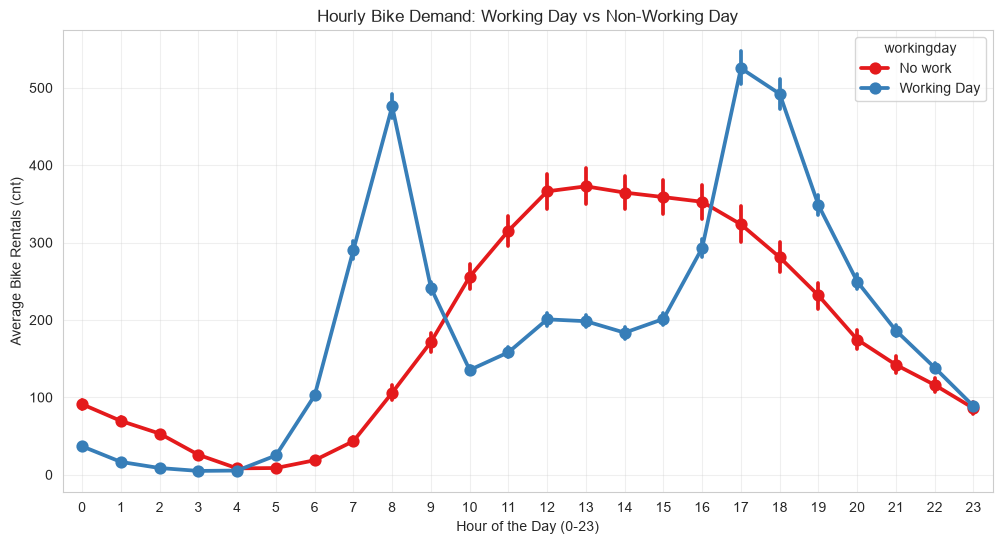

In [13]:
# Set the figure size
plt.figure(figsize=(12, 6))

# Line plot showing average rental count by hour, split by workingday
sns.pointplot(data=df, x='hr', y='cnt', hue='workingday', palette='Set1')

# Add titles and labels
plt.title('Hourly Bike Demand: Working Day vs Non-Working Day')
plt.xlabel('Hour of the Day (0-23)')
plt.ylabel('Average Bike Rentals (cnt)')
plt.grid(True, alpha=0.3)

# Display the plot
plt.show()

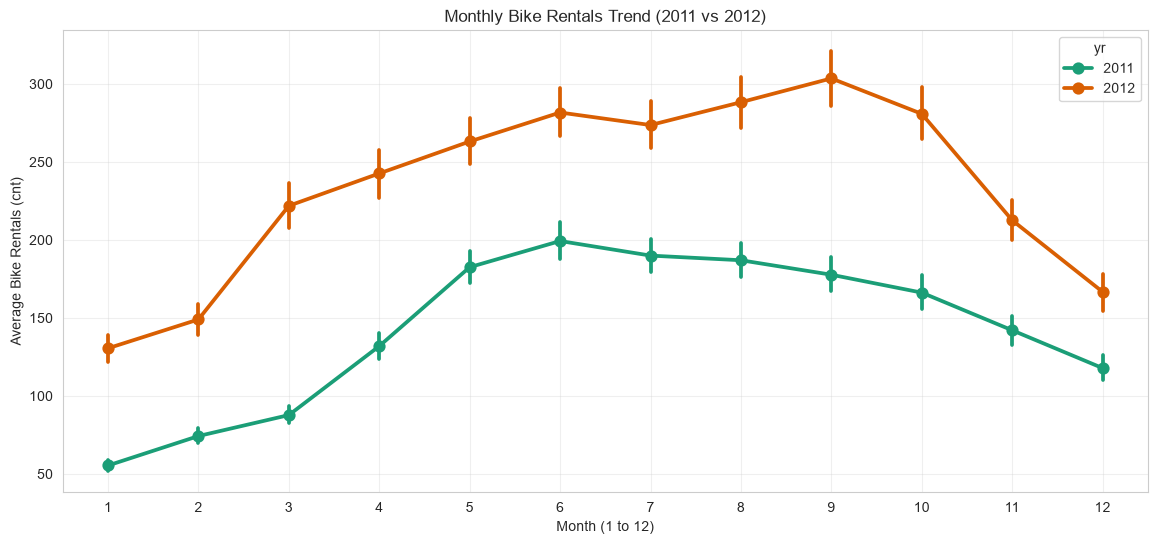

In [14]:
plt.figure(figsize=(14, 6))
# Using pointplot to show monthly trends across both years
sns.pointplot(data=df, x='mnth', y='cnt', hue='yr', palette='Dark2')
plt.title('Monthly Bike Rentals Trend (2011 vs 2012)')
plt.xlabel('Month (1 to 12)')
plt.ylabel('Average Bike Rentals (cnt)')
plt.grid(True, alpha=0.3)
plt.show()

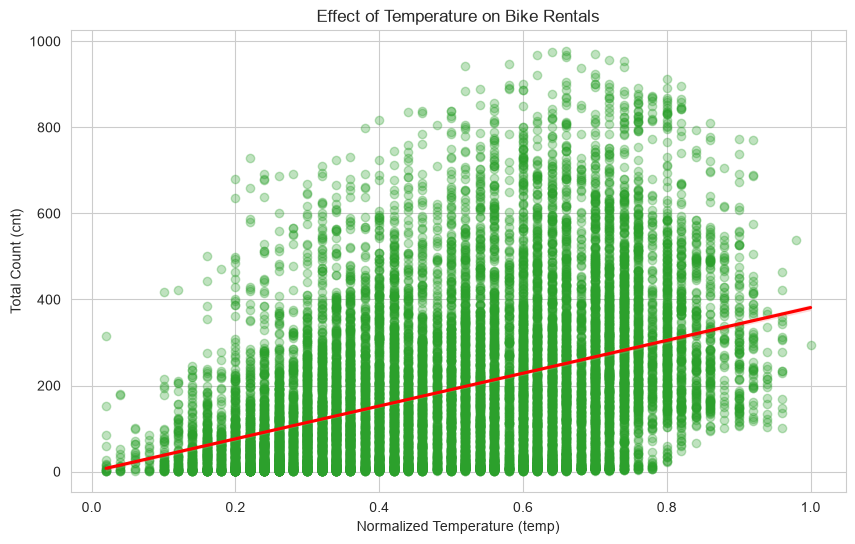

In [15]:
plt.figure(figsize=(10, 6))
# Scatter plot with regression line to show temperature impact
sns.regplot(data=df, x='temp', y='cnt', scatter_kws={'alpha':0.3, 'color':'#2ca02c'}, line_kws={'color':'red'})
plt.title('Effect of Temperature on Bike Rentals')
plt.xlabel('Normalized Temperature (temp)')
plt.ylabel('Total Count (cnt)')
plt.show()

C:\Users\jayat\AppData\Local\Temp\ipykernel_18636\2103098878.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='weekday', y='cnt', palette='mako')


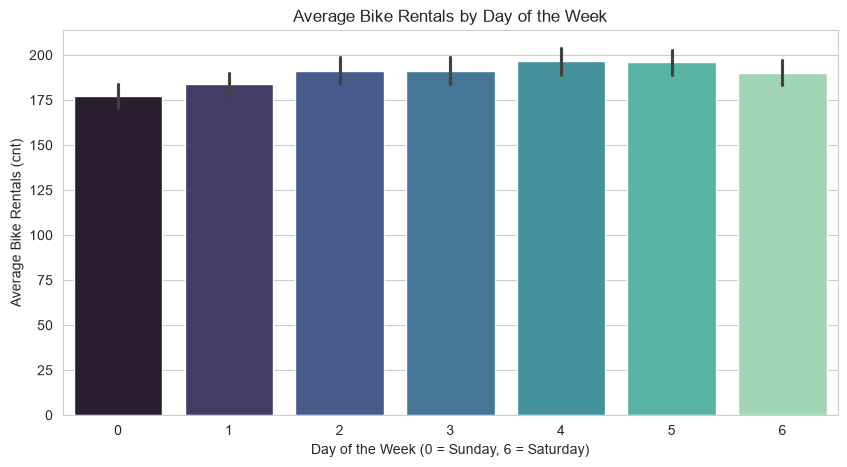

In [16]:
plt.figure(figsize=(10, 5))
# Barplot for days of the week
sns.barplot(data=df, x='weekday', y='cnt', palette='mako')
plt.title('Average Bike Rentals by Day of the Week')
plt.xlabel('Day of the Week (0 = Sunday, 6 = Saturday)')
plt.ylabel('Average Bike Rentals (cnt)')
plt.show()